# 03 — Du comptage au réseau : entrées one-hot et matrice de poids `W`

**Chapitre 1** · durée conseillée : 20 min · CPU uniquement

![Parcours du chapitre](figures/00_parcours.svg)

## 1. Pourquoi construire un réseau alors que nous avons déjà `P` ?

Notre premier modèle fonctionne : il compte les transitions et obtient une NLL de 2,45. **Pour un simple bigramme, compter est même la méthode la plus directe.** Nous ne prétendons pas que le réseau fera mieux.

**Le nouveau défi :** obtenir le *même genre* de table **sans compter**. On part d'une matrice de nombres aléatoires, et on la corrige grâce aux gradients.

| Modèle par comptage (notebooks 01–02) | Modèle neuronal (notebooks 03–06) |
|:---|:---|
| On compte les transitions dans `N`. | On tire au hasard des nombres dans `W`. |
| On divise chaque ligne de `N` par sa somme. | On transforme chaque ligne de `W` en probabilités (softmax, notebook 04). |
| Une ligne = « qu'est-ce qui suit ce caractère ? » | Une ligne = « quels scores donner aux caractères suivants ? » |
| Les probabilités viennent directement des données. | Les probabilités viennent de poids ajustés par la loss. |

**Pourquoi s'en donner la peine ?** Compter ne passe pas à l'échelle. Avec 3 caractères de contexte, il faudrait déjà 27³ × 27 ≈ 530 000 cases, presque toutes vides. Avec un réseau, on pourra **agrandir le contexte sans tout compter** : c'est exactement ce que fera le Transformer du chapitre 2. Le bigramme est le cas le plus simple pour comprendre la mécanique, car on connaît la bonne réponse (la table `P`).

**Fil conducteur :** `caractère courant → one-hot → ligne de W → scores → probabilités → loss → mise à jour de W`. Ce notebook traite les trois premières flèches.

In [1]:
# Préparation : imports et petit module partagé du chapitre
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigramme  # fichier bigramme.py, à côté de ce notebook
from bigramme import SEED, plot_matrice_caracteres

words = bigramme.charger_prenoms()
chars, stoi, itos = bigramme.construire_vocabulaire(words)
print(f"{len(words):,} prénoms · vocabulaire de {len(stoi)} symboles · PyTorch {torch.__version__}")

N = bigramme.compter_bigrammes(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)

32,033 prénoms · vocabulaire de 27 symboles · PyTorch 2.14.1+cu130


## 2. Les entrées et les bonnes réponses

Un réseau ne s'entraîne pas directement sur la chaîne `"emma"`. Il reçoit, pour **chaque transition**, une **entrée** et une **réponse attendue**. Un prénom de 4 lettres cache ainsi **cinq exercices** :

| exercice | caractère donné `x` | réponse attendue `y` | indices `(x, y)` |
|---:|:---:|:---:|:---:|
| 1 | `.` | `e` | `(0, 5)` |
| 2 | `e` | `m` | `(5, 13)` |
| 3 | `m` | `m` | `(13, 13)` |
| 4 | `m` | `a` | `(13, 1)` |
| 5 | `a` | `.` | `(1, 0)` |

- `xs` contient les **entrées** : ce que le réseau **voit** ;
- `ys` contient les **bonnes réponses** : ce qu'on lui **demande de prédire**. Elles servent à calculer la loss, comme au notebook 02.

**Question à la classe :** pourquoi `m` apparaît-il deux fois dans `xs` ? Parce que deux bigrammes d'`emma` commencent par `m` : `m→m` et `m→a`. **Le même contexte peut avoir plusieurs bonnes réponses.** Aucun modèle bigramme ne peut avoir raison à 100 % sur les deux.

In [2]:
sequence = ["."] + list("emma") + ["."]
transitions = list(zip(sequence, sequence[1:]))

xs_small = torch.tensor([stoi[ch1] for ch1, ch2 in transitions], dtype=torch.long)
ys_small = torch.tensor([stoi[ch2] for ch1, ch2 in transitions], dtype=torch.long)

for t, ((ch1, ch2), x, y) in enumerate(zip(transitions, xs_small, ys_small), start=1):
    print(f"Exemple {t} : entrée '{ch1}' (x={x.item():2d}) → vraie réponse '{ch2}' (y={y.item():2d})")
print("\nxs_small =", xs_small.tolist(), "| forme", tuple(xs_small.shape))
print("ys_small =", ys_small.tolist(), "| forme", tuple(ys_small.shape))

Exemple 1 : entrée '.' (x= 0) → vraie réponse 'e' (y= 5)
Exemple 2 : entrée 'e' (x= 5) → vraie réponse 'm' (y=13)
Exemple 3 : entrée 'm' (x=13) → vraie réponse 'm' (y=13)
Exemple 4 : entrée 'm' (x=13) → vraie réponse 'a' (y= 1)
Exemple 5 : entrée 'a' (x= 1) → vraie réponse '.' (y= 0)

xs_small = [0, 5, 13, 13, 1] | forme (5,)
ys_small = [5, 13, 13, 1, 0] | forme (5,)


## 3. Pourquoi ne pas donner directement l'indice `13` au réseau ?

Le nombre `13` qui représente `m` est une **étiquette arbitraire**. Si on le donnait tel quel à une multiplication, le réseau « croirait » que `m` vaut 13 fois `a`, ou que `l` (12) est proche de `m` parce que leurs numéros sont voisins. C'est faux.

Solution simple : **une case par symbole**.
- un vecteur de **27 cases**, une par caractère possible ;
- **26 zéros** et **un seul `1`**, dans la case du caractère observé.

C'est l'encodage **one-hot** (« une seule case allumée »). Il ne dit rien du sens des lettres : il dit seulement **laquelle est présente**.

> **Forme :** 5 exemples, et pour chacun un vecteur de 27 valeurs. Donc `xs_small` de forme `(5,)` devient `F.one_hot(xs_small)` de forme `(5, 27)`.

Forme des indices      : (5,)
Forme des one-hot      : (5, 27)
Case allumée par ligne : [0, 5, 13, 13, 1]
Nombre de 1 par ligne  : [1.0, 1.0, 1.0, 1.0, 1.0]


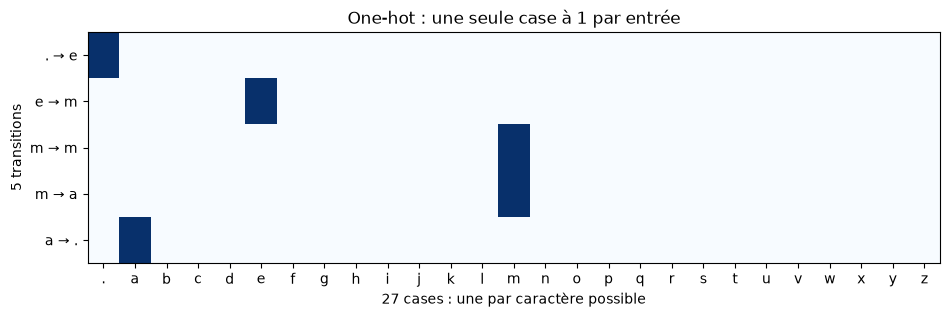

In [3]:
# F.one_hot renvoie des entiers ; .float() est nécessaire pour la multiplication par W (des réels).
xenc_small = F.one_hot(xs_small, num_classes=27).float()

print("Forme des indices      :", tuple(xs_small.shape))
print("Forme des one-hot      :", tuple(xenc_small.shape))
print("Case allumée par ligne :", xenc_small.argmax(dim=1).tolist())
print("Nombre de 1 par ligne  :", xenc_small.sum(dim=1).tolist())

fig, ax = plt.subplots(figsize=(11, 3))
ax.imshow(xenc_small.numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(27), [itos[i] for i in range(27)])
ax.set_yticks(range(5), [f"{a} → {b}" for a, b in transitions])
ax.set_xlabel("27 cases : une par caractère possible"); ax.set_ylabel("5 transitions")
ax.set_title("One-hot : une seule case à 1 par entrée")
plt.show()

## 4. Que fait vraiment la multiplication `one-hot @ W` ?

![One-hot fois W](figures/03_one_hot_selection.svg)

Ne partons pas tout de suite d'une matrice 27 × 27. Prenons **3 caractères** (`a`, `b`, `c`) et une matrice de **scores** (pas encore des probabilités). Chaque ligne correspond au caractère *courant*, chaque colonne au caractère *suivant* :

$$
W_{\mathrm{mini}}=
\begin{bmatrix} 2 & 1 & 0\\ 4 & 5 & 6\\ 7 & 8 & 9 \end{bmatrix},
\qquad x_b=\begin{bmatrix}0 & 1 & 0\end{bmatrix}.
$$

Calculons colonne par colonne :

$$
x_b W_{\mathrm{mini}}
= \big[\,0\cdot 2 + 1\cdot 4 + 0\cdot 7,\;\; 0\cdot 1 + 1\cdot 5 + 0\cdot 8,\;\; 0\cdot 0 + 1\cdot 6 + 0\cdot 9\,\big]
= \begin{bmatrix} 4 & 5 & 6 \end{bmatrix}.
$$

Les `0` annulent les lignes `a` et `c`, le `1` conserve **toute la ligne `b`**. Ce produit est une **sélection de ligne**, pas un mélange.

**Avant d'exécuter :** `[4, 5, 6]` est-il une distribution de probabilités ? Non : ces nombres ne somment pas à 1. Ce sont des **scores**. Les transformer en probabilités sera l'objet du notebook 04.

In [4]:
W_mini = torch.tensor([
    [2., 1., 0.],  # scores si le caractère courant est 'a'
    [4., 5., 6.],  # scores si le caractère courant est 'b'
    [7., 8., 9.],  # scores si le caractère courant est 'c'
])
x_b = torch.tensor([0., 1., 0.])

resultat = x_b @ W_mini
print("x_b @ W_mini =", resultat.tolist())
print("ligne b      =", W_mini[1].tolist())
assert torch.equal(resultat, W_mini[1])     # une identité algébrique, pas une coïncidence
print("Avec [1,0,0] :", (torch.tensor([1., 0., 0.]) @ W_mini).tolist(), "= ligne a")

x_b @ W_mini = [4.0, 5.0, 6.0]
ligne b      = [4.0, 5.0, 6.0]
Avec [1,0,0] : [2.0, 1.0, 0.0] = ligne a


## 5. La même chose sur les cinq bigrammes d'`emma`

Revenons à **27 caractères**. On tire une matrice `W` de forme `(27, 27)` au hasard, selon une loi normale centrée réduite (`torch.randn`). Pour l'instant, elle sert seulement à **observer le mécanisme**. Aucune optimisation n'a lieu ici.

$$
\underbrace{X_{\text{one-hot}}}_{(5,\,27)}\;@\;\underbrace{W}_{(27,\,27)}\;=\;\underbrace{\text{scores}}_{(5,\,27)}
$$

**Lire les trois dimensions :**
- **5** : on prédit le caractère suivant pour cinq transitions ;
- **27 au milieu** : les 27 cases du one-hot correspondent aux 27 lignes de `W`. Ces deux dimensions **doivent** être égales ;
- **27 en sortie** : pour chaque entrée, on obtient 27 scores, un par caractère suivant possible.

Dans `emma`, les exemples 3 et 4 ont la **même entrée** (`m`). Ils sélectionnent donc **la même ligne de `W`** et reçoivent **les mêmes scores**, alors que leurs bonnes réponses diffèrent. C'est la limite fondamentale du bigramme : il ne connaît pas ce qui précède.

xenc_small : (5, 27)  @  W : (27, 27)  =  scores : (5, 27)
one-hot @ W == W[xs_small] ? True
Exemples 3 et 4 : même entrée 'm' ? True | mêmes 27 scores ? True
Nombre de paramètres de W : 729 = autant que de cases dans N


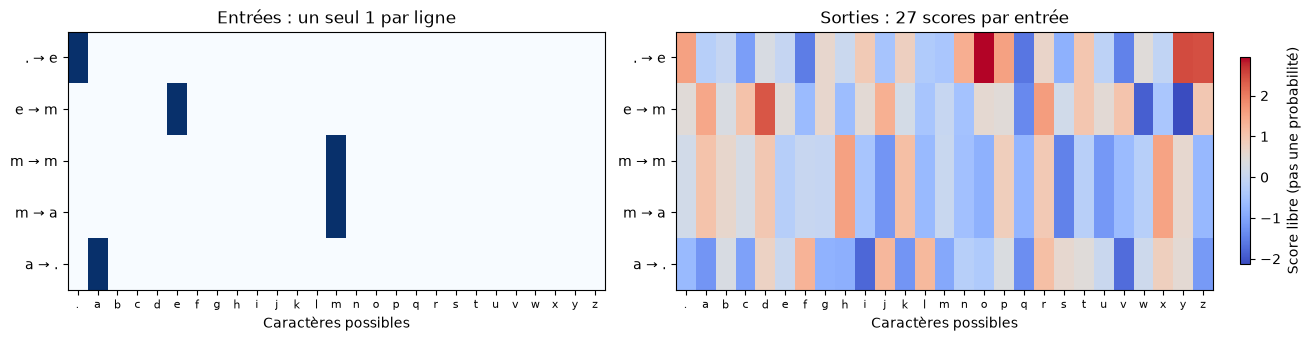

In [5]:
g = torch.Generator().manual_seed(SEED)
W = torch.randn((27, 27), generator=g)

scores_5 = xenc_small @ W
print("xenc_small :", tuple(xenc_small.shape), " @  W :", tuple(W.shape), " =  scores :", tuple(scores_5.shape))
print("one-hot @ W == W[xs_small] ?", torch.allclose(scores_5, W[xs_small]))
print("Exemples 3 et 4 : même entrée 'm' ?", xs_small[2].item() == xs_small[3].item(),
      "| mêmes 27 scores ?", torch.allclose(scores_5[2], scores_5[3]))
print("Nombre de paramètres de W :", W.numel(), "= autant que de cases dans N")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.3), constrained_layout=True)
axes[0].imshow(xenc_small.numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[0].set_title("Entrées : un seul 1 par ligne")
im = axes[1].imshow(scores_5.numpy(), cmap="coolwarm", aspect="auto")
axes[1].set_title("Sorties : 27 scores par entrée")
for ax in axes:
    ax.set_xticks(range(27), [itos[i] for i in range(27)], fontsize=8)
    ax.set_yticks(range(5), [f"{a} → {b}" for a, b in transitions])
    ax.set_xlabel("Caractères possibles")
fig.colorbar(im, ax=axes[1], label="Score libre (pas une probabilité)", shrink=0.8)
plt.show()

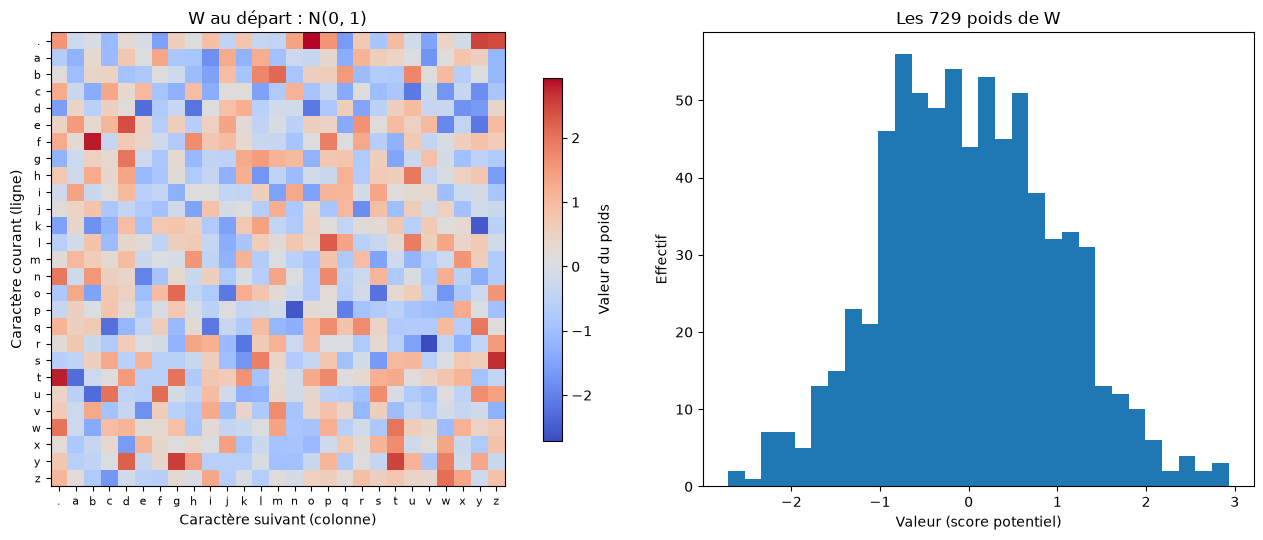

Des scores négatifs sont autorisés dans W : True


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
plot_matrice_caracteres(W, itos, title="W au départ : N(0, 1)", cbar_label="Valeur du poids",
                        cmap="coolwarm", ax=axes[0])
axes[1].hist(W.flatten().numpy(), bins=30)
axes[1].set(title="Les 729 poids de W", xlabel="Valeur (score potentiel)", ylabel="Effectif")
plt.tight_layout(); plt.show()
print("Des scores négatifs sont autorisés dans W :", bool((W < 0).any()))

**Comparez avec la carte de `N` du notebook 01 :** ici il n'y a aucune structure. `W` ne sait **rien** des prénoms. Tout son savoir viendra de l'entraînement (notebook 06).

> **Lien avec le chapitre 2.** Construire un one-hot de 27 cases pour lire une ligne est coûteux. PyTorch fournit `nn.Embedding(27, 27)`, qui fait **directement** `W[indice]`. C'est exactement la même opération : on le vérifiera au chapitre 2.

## 6. Le problème qui mène au notebook 04

Nous savons maintenant **partir d'un caractère et obtenir 27 scores modifiables**. Mais ces scores :
- peuvent être **négatifs** ;
- ne somment **pas à 1** ;
- ne sont donc **pas** des probabilités ;
- et on **ne peut pas** encore leur appliquer la NLL du notebook 02, qui a besoin de la probabilité de la vraie réponse.

**Mini-vérification orale (30 s) :** si le caractère courant est `m`, quelle ligne de `W` est sélectionnée ? Pourquoi les deux `m` d'`emma` ont-ils exactement les mêmes scores ? Que manque-t-il pour calculer la loss ?

**La question du notebook 04 :** comment transformer **n'importe quelle** ligne de scores en 27 probabilités positives de somme 1 ?

## Références
- I. Goodfellow, Y. Bengio et A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, chapitre 6 (réseaux *feedforward*) et section 15.5 (représentations distribuées vs one-hot).
- Y. Bengio et al., [*A Neural Probabilistic Language Model*](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), JMLR 2003 : le premier modèle de langage neuronal, qui remplace le comptage par des paramètres appris.
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) et le dépôt [makemore](https://github.com/karpathy/makemore), dont viennent `names.txt` et l'esprit de ce chapitre.
- Documentation PyTorch : [`F.one_hot`](https://pytorch.org/docs/stable/generated/torch.nn.functional.one_hot.html), [`nn.Embedding`](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html).